In [28]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from recover.constants import DATA_DIR

In [30]:
from recover.dataset import RasterDataset, raster_to_df
from recover.visualise import plot_cell_over_time, plot_single_band, set_plot_defaults

set_plot_defaults()

# Read raw data

In [31]:
luh = pd.read_parquet(DATA_DIR / 'luh_timeseries.parquet')
luh = luh.fillna(0.0)

esa = pd.read_parquet(DATA_DIR / 'esa_timeseries.parquet')

In [32]:
luh.info()

<class 'pandas.DataFrame'>
RangeIndex: 1054560 entries, 0 to 1054559
Data columns (total 10 columns):
 #   Column  Non-Null Count    Dtype  
---  ------  --------------    -----  
 0   cell    1054560 non-null  float64
 1   pastr   1054560 non-null  float64
 2   primf   1054560 non-null  float64
 3   primn   1054560 non-null  float64
 4   range   1054560 non-null  float64
 5   secdf   1054560 non-null  float64
 6   secdn   1054560 non-null  float64
 7   urban   1054560 non-null  float64
 8   crops   1054560 non-null  float64
 9   year    1054560 non-null  float64
dtypes: float64(10)
memory usage: 80.5 MB


In [33]:
esa.info()

<class 'pandas.DataFrame'>
RangeIndex: 251472 entries, 0 to 251471
Data columns (total 17 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   cell                  251472 non-null  float64
 1   ESA_BareAreas         251472 non-null  float64
 2   ESA_Cropland          251472 non-null  float64
 3   ESA_Forest_Bl_Dec     251472 non-null  float64
 4   ESA_Forest_Bl_Ev      251472 non-null  float64
 5   ESA_Forest_Woodland   251472 non-null  float64
 6   ESA_ForestMosaic      251472 non-null  float64
 7   ESA_Grassland         251472 non-null  float64
 8   ESA_GrasslandMosaic   251472 non-null  float64
 9   ESA_Mangrove          251472 non-null  float64
 10  ESA_Shrubland         251472 non-null  float64
 11  ESA_SnowIce           251472 non-null  float64
 12  ESA_SparseVegetation  251472 non-null  float64
 13  ESA_Urban             251472 non-null  float64
 14  ESA_Varzea            251472 non-null  float64
 15  ESA_Water  

# Preprocess

In [34]:
esa_ds = RasterDataset(esa)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']


Finished building array with shape (31, 15, 157, 180)


## Join tabular and biome data

In [35]:
biomes = raster_to_df(DATA_DIR / 'NTAmericas_efgs_50km.tif')
biomes

DATA SHAPE: (1, 157, 180)
METADATA:
{'count': 1,
 'crs': CRS.from_wkt('PROJCS["unknown",GEOGCS["unknown",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Albers_Conic_Equal_Area"],PARAMETER["latitude_of_center",-5],PARAMETER["longitude_of_center",-65],PARAMETER["standard_parallel_1",10],PARAMETER["standard_parallel_2",-20],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]]'),
 'driver': 'GTiff',
 'dtype': 'uint8',
 'height': 157,
 'nodata': 255.0,
 'transform': Affine(50000.0, 0.0, -5516832.203866814,
       0.0, -50000.0, 3706678.156476609),
 'width': 180}


,NTAmericas_efgs_50km
cell,
11,11
12,11
13,11
188,16
189,16
...,...
28012,7
28187,7
28188,7


In [36]:
biome_classes = pd.read_excel(DATA_DIR / 'ESA-LC_Biome_proportions.xlsx')[['our_efg', 'Biome_Classes']].rename(columns={'Biome_Classes': 'biome_classes'})
biome_classes.index = biome_classes.index + 1
display(biome_classes)

biomes = biomes.join(biome_classes, how='left', on='NTAmericas_efgs_50km')
biomes

,our_efg,biome_classes
1,Cool deserts and semi-deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
2,Hyper-arid deserts,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
3,Intertidal forests and shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Mangrov...
4,Oceanic cool temperate rainforests,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
5,Pyric tussock savannas,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
6,Seasonal floodplain marshes,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
8,Seasonally dry tropical shrublands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
9,Temperate alpine grasslands and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
10,Temperate subhumid grasslands,ESA_Forest_Bl_Ev|ESA_Shrubland


,NTAmericas_efgs_50km,our_efg,biome_classes
cell,,,
11,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
12,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
13,11,Temperate woodlands,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Forest_...
188,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
189,16,Tropical-subtropical dry forests and thickets,ESA_Forest_Bl_Dec|ESA_Forest_Bl_Ev|ESA_Shrubland
...,...,...,...
28012,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28187,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation
28188,7,Seasonally dry temperate heaths and shrublands,ESA_BareAreas|ESA_Shrubland|ESA_SparseVegetation


In [37]:
def compute_habitat_fraction(esa_df, biomes_df):
    df = esa_df.join(biomes_df, how='left', on='cell')
    out = pd.Series(index=df.index)
    for biome, data in df.groupby('our_efg'):
        print('---', biome, '---')
        cols = data['biome_classes'].iloc[0].split('|')
        habitat_fraction = data[cols].sum(axis=1).rename('habitat')
        out.loc[data.index] = habitat_fraction
        print(data[cols].mean(), '\n')
        print(habitat_fraction.describe(), '\n')

    return out

esa_with_hab = esa.copy()
esa_with_hab['habitat'] = compute_habitat_fraction(esa, biomes)

--- Cool deserts and semi-deserts ---
ESA_BareAreas           0.013850
ESA_Shrubland           0.527584
ESA_SparseVegetation    0.432413
dtype: float64 

count    1178.000000
mean        0.973847
std         0.049435
min         0.750767
25%         0.973749
50%         0.995088
75%         0.999113
max         1.000000
Name: habitat, dtype: float64 

--- Hyper-arid deserts ---
ESA_BareAreas           0.522571
ESA_Shrubland           0.121442
ESA_SparseVegetation    0.198175
dtype: float64 

count    4805.000000
mean        0.842189
std         0.208288
min         0.000000
25%         0.784572
50%         0.928775
75%         0.988925
max         1.000000
Name: habitat, dtype: float64 

--- Intertidal forests and shrublands ---
ESA_Forest_Bl_Dec    0.010493
ESA_Forest_Bl_Ev     0.255790
ESA_Mangrove         0.163826
ESA_Shrubland        0.073343
ESA_Varzea           0.023471
dtype: float64 

count    4960.000000
mean        0.526923
std         0.238779
min         0.000000
25%       

In [38]:
esa_hab_ds = RasterDataset(esa_with_hab)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water', 'habitat']


Finished building array with shape (31, 16, 157, 180)


## Fill missing LUH data (non-land)

In [39]:
luh_ds = RasterDataset(luh)
luh['water'] = (1.0 - luh[luh_ds.bands].sum(axis=1))
luh_ds = RasterDataset(luh)
luh.isna().sum()
luh_ds.data.isna().sum()

Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops']
Finished building array with shape (130, 8, 157, 180)
Initialising raster dataset with bands ['pastr', 'primf', 'primn', 'range', 'secdf', 'secdn', 'urban', 'crops', 'water']
Finished building array with shape (130, 9, 157, 180)


pastr    0
primf    0
primn    0
range    0
secdf    0
secdn    0
urban    0
crops    0
year     0
water    0
dtype: int64

# Visualise

## Single cell over time

<Axes: title={'center': 'Cell 12 fractions over time'}, xlabel='year'>

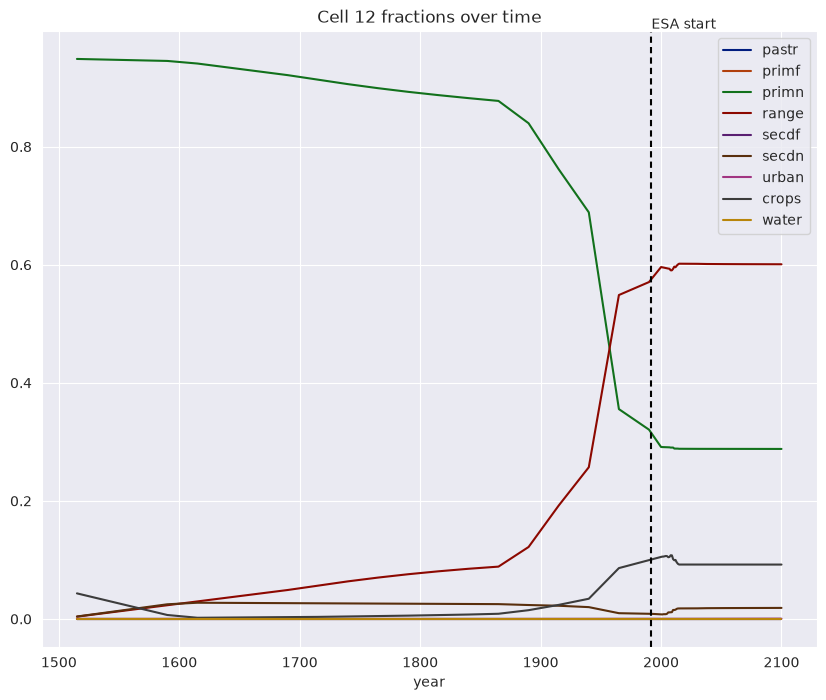

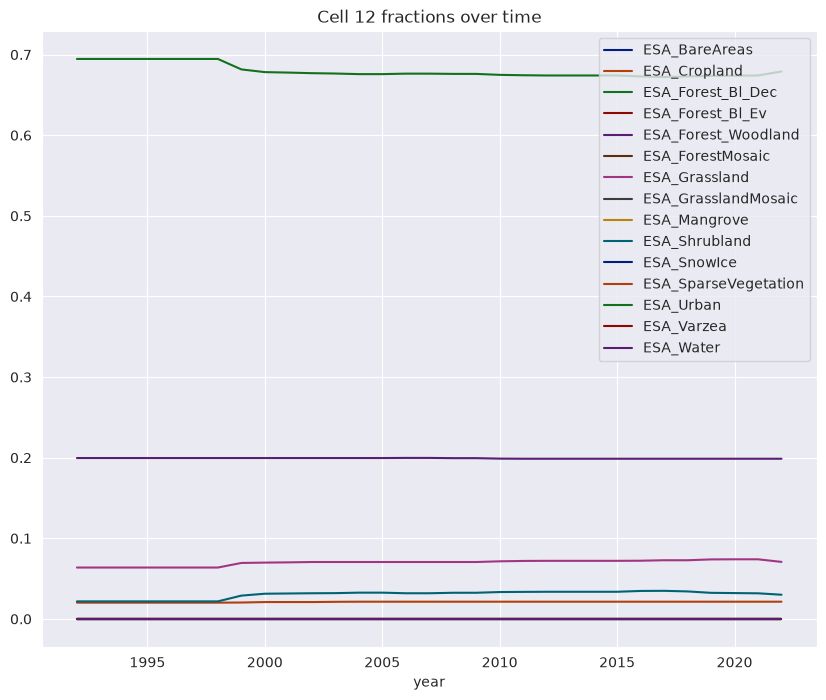

In [40]:
set_plot_defaults()
plot_cell_over_time(luh_ds, cell_id=12)
plt.axvline(1992, color='k', dashes=(3, 2))
plt.text(1992, 1.0, 'ESA start')

plot_cell_over_time(esa_ds, cell_id=12)

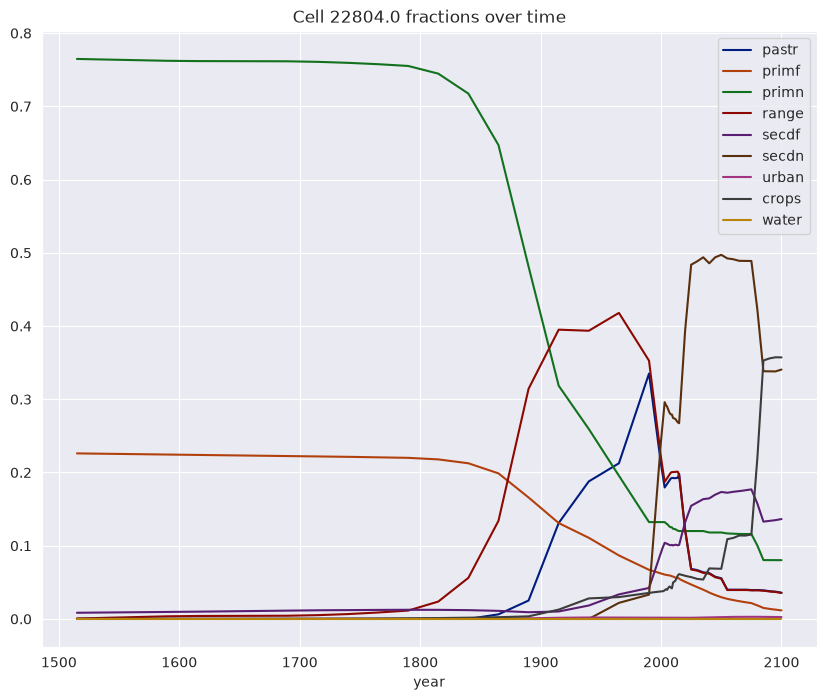

In [41]:
plot_cell_over_time(luh_ds);

<Axes: title={'center': 'Per biome habitat fraction over time'}, xlabel='year'>

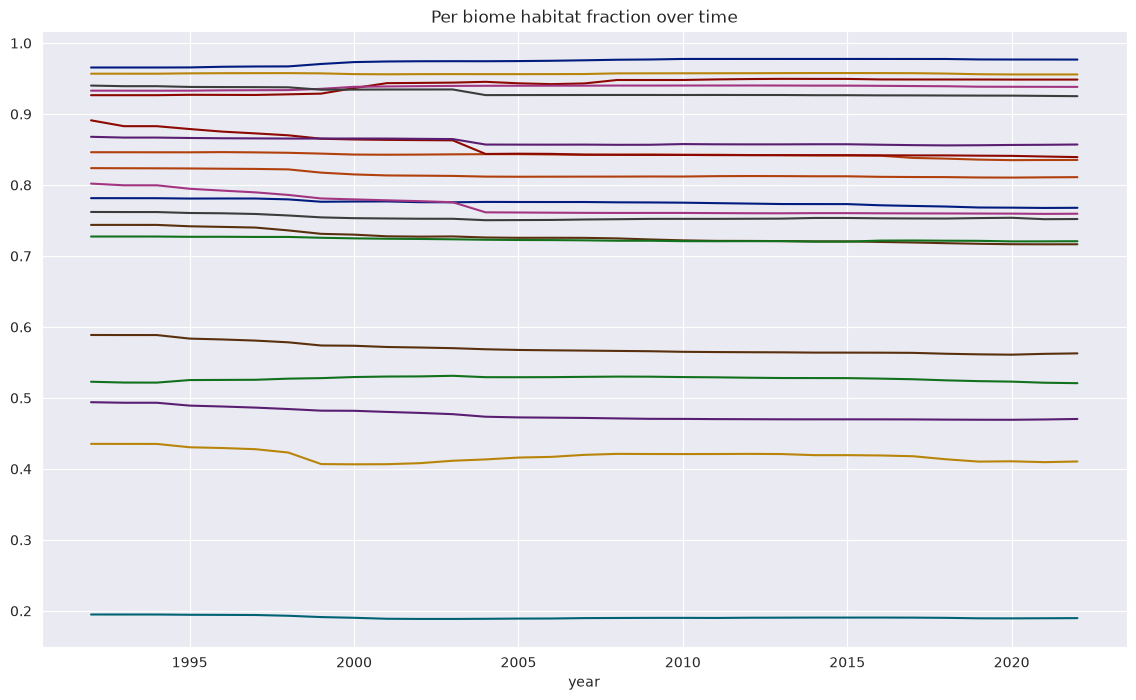

In [42]:
habitat_over_time = (
    esa_hab_ds.data.join(biomes)
    .set_index(esa_hab_ds.time_col)
    .groupby(['our_efg', esa_hab_ds.time_col])
    ['habitat']
    .mean()
    .unstack()
    .T
)

habitat_over_time.plot(legend=False, title='Per biome habitat fraction over time', figsize=(14, 8))

# Evaluation per time slice

In [43]:
common_years = sorted(list(set(luh['year']).intersection(set(esa['year']))))
common_years

[1992.0,
 1993.0,
 1994.0,
 1995.0,
 1996.0,
 1997.0,
 1998.0,
 1999.0,
 2000.0,
 2001.0,
 2002.0,
 2003.0,
 2004.0,
 2005.0,
 2006.0,
 2007.0,
 2008.0,
 2009.0,
 2010.0,
 2011.0,
 2012.0,
 2013.0,
 2014.0,
 2015.0,
 2016.0,
 2017.0,
 2018.0,
 2019.0,
 2020.0,
 2021.0,
 2022.0]

In [44]:
from recover.evaluation import evaluate
from recover.models.linear import MultiOutputOLS, SimplexRegression
import time
from tqdm import tqdm

def get_stepped_folds(common_years: list, train_window: int = 15, test_window: int = 5):
    for fold in range(len(common_years) - (train_window + test_window) + 1):
        test_start = fold
        train_start = fold + test_window
        train_end = train_start + train_window

        test_years = common_years[test_start:train_start]
        train_years = common_years[train_start:train_end]
        yield train_years, test_years

models = {
    'simplex': SimplexRegression,
    'ols': MultiOutputOLS,
}


### Sliding windows
```
1 - [test][    train    ]
2 -   [test][    train    ]
3 -     [test][    train    ]
4 -       [test][    train    ]
...
```

In [90]:
results = []
for model_name, model_cls in models.items():
    for fold_id, (train_years, test_years) in tqdm(enumerate(get_stepped_folds(common_years))):
        X_train = luh_ds.get_time_slice(train_years)
        y_train = esa_ds.get_time_slice(train_years)
        X_test = luh_ds.get_time_slice(test_years)
        y_test = esa_ds.get_time_slice(test_years)

        model = model_cls()
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        t1 = time.perf_counter()
        y_pred = model.predict(X_test)
        fold_eval = evaluate(y_test, y_pred, name=f'{model_name}')
        fold_eval['fold_id'] = fold_id
        fold_eval['fit_time_seconds'] = t1 - t0
        results.append(fold_eval)
    
    display(pd.concat(results, axis=1).T)
    

0it [00:00, ?it/s]

12it [09:55, 49.64s/it]


,kl_divergence,js_divergence,mean_absolute_error,fold_id,fit_time_seconds
simplex,0.593591,0.147253,0.049337,0.0,50.279425
simplex,0.593020,0.147088,0.049305,1.0,47.263759
simplex,0.591657,0.146767,0.049245,2.0,58.011050
simplex,0.590463,0.146777,0.049273,3.0,49.141596
simplex,0.588953,0.146449,0.049211,4.0,38.085812
simplex,0.587414,0.146084,0.049134,5.0,38.346092
simplex,0.586455,0.145938,0.049106,6.0,42.239310
simplex,0.585775,0.145709,0.049058,7.0,48.053433
simplex,0.586340,0.145722,0.049049,8.0,62.332611
simplex,0.586776,0.145729,0.049042,9.0,68.926067


12it [00:26,  2.23s/it]


,kl_divergence,js_divergence,mean_absolute_error,fold_id,fit_time_seconds
simplex,0.593591,0.147253,0.049337,0.0,50.279425
simplex,0.593020,0.147088,0.049305,1.0,47.263759
simplex,0.591657,0.146767,0.049245,2.0,58.011050
simplex,0.590463,0.146777,0.049273,3.0,49.141596
simplex,0.588953,0.146449,0.049211,4.0,38.085812
simplex,0.587414,0.146084,0.049134,5.0,38.346092
simplex,0.586455,0.145938,0.049106,6.0,42.239310
simplex,0.585775,0.145709,0.049058,7.0,48.053433
simplex,0.586340,0.145722,0.049049,8.0,62.332611
simplex,0.586776,0.145729,0.049042,9.0,68.926067


### Only test slides
Train a single model with the latest available data and test on windows further "behind"
```
1 - [test]      [    train    ]
2 -   [test]    [    train    ]
3 -     [test]  [    train    ]
4 -       [test][    train    ]
...
```

In [91]:
results_gap = []
for model_name, model_cls in models.items():
    # Single training set and fitted model
    train_years, _ = list(get_stepped_folds(common_years))[-1]
    X_train = luh_ds.get_time_slice(train_years)
    y_train = esa_ds.get_time_slice(train_years)
    print(f'Training {model_name} with years {train_years}')
    model = model_cls()
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t1 = time.perf_counter()

    for _, test_years in get_stepped_folds(common_years):
        X_test = luh_ds.get_time_slice(test_years)
        y_test = esa_ds.get_time_slice(test_years)

        y_pred = model.predict(X_test)
        fold_eval = evaluate(y_test, y_pred, name=f'{model_name}')
        fold_eval['test_start'] = test_years[0]
        fold_eval['test_end'] = test_years[-1]
        fold_eval['fit_time_seconds'] = t1 - t0
        results_gap.append(fold_eval)
    
pd.concat(results_gap, axis=1).T

Training simplex with years [2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0, 2020.0, 2021.0, 2022.0]
Training ols with years [2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0, 2020.0, 2021.0, 2022.0]


,kl_divergence,js_divergence,mean_absolute_error,test_start,test_end,fit_time_seconds
simplex,0.589027,0.146919,0.049322,1992.0,1996.0,39.295471
simplex,0.588306,0.146664,0.049263,1993.0,1997.0,39.295471
simplex,0.587644,0.146412,0.049201,1994.0,1998.0,39.295471
simplex,0.587084,0.146149,0.049138,1995.0,1999.0,39.295471
simplex,0.586543,0.145877,0.049072,1996.0,2000.0,39.295471
simplex,0.586001,0.145622,0.049007,1997.0,2001.0,39.295471
simplex,0.585724,0.145451,0.048961,1998.0,2002.0,39.295471
simplex,0.585646,0.145342,0.048927,1999.0,2003.0,39.295471
simplex,0.586267,0.145344,0.048924,2000.0,2004.0,39.295471
simplex,0.586978,0.145405,0.048936,2001.0,2005.0,39.295471


# Reconstruct full ESA history

In [63]:
def fit_predict_full(luh_ds, esa_ds, common_years, model_cls):
    model = model_cls()
    X = luh_ds.get_time_slice(common_years)
    y = esa_ds.get_time_slice(common_years)
    print(f'Fitting model with shapes X = {X.shape}, y = {y.shape}')
    model.fit(X, y)

    X_test = luh_ds.data.drop('year', axis=1)
    print(f'Predicting shape = {X_test.shape}')
    preds = model.predict(X_test)
    print(f'Adding year column back to computed preds of shape {preds.shape}')
    pred_df = pd.concat([
        pd.DataFrame(preds, index=luh_ds.data.index, columns=y.columns),
        (luh_ds.data['year'])
    ], axis=1)
    return pred_df, model

In [64]:
ols_df, ols_model = fit_predict_full(luh_ds, esa_ds, common_years, MultiOutputOLS)
ols_df.shape

Fitting model with shapes X = (251472, 9), y = (251472, 15)
Predicting shape = (1054560, 9)
Adding year column back to computed preds of shape (1054560, 15)


(1054560, 16)

In [65]:
pred_df.info()

<class 'pandas.DataFrame'>
Index: 1054560 entries, 11.0 to 28190.0
Data columns (total 16 columns):
 #   Column                Non-Null Count    Dtype  
---  ------                --------------    -----  
 0   ESA_BareAreas         1054560 non-null  float64
 1   ESA_Cropland          1054560 non-null  float64
 2   ESA_Forest_Bl_Dec     1054560 non-null  float64
 3   ESA_Forest_Bl_Ev      1054560 non-null  float64
 4   ESA_Forest_Woodland   1054560 non-null  float64
 5   ESA_ForestMosaic      1054560 non-null  float64
 6   ESA_Grassland         1054560 non-null  float64
 7   ESA_GrasslandMosaic   1054560 non-null  float64
 8   ESA_Mangrove          1054560 non-null  float64
 9   ESA_Shrubland         1054560 non-null  float64
 10  ESA_SnowIce           1054560 non-null  float64
 11  ESA_SparseVegetation  1054560 non-null  float64
 12  ESA_Urban             1054560 non-null  float64
 13  ESA_Varzea            1054560 non-null  float64
 14  ESA_Water             1054560 non-null  float64

In [75]:
simplex_df, simplex_model = fit_predict_full(luh_ds, esa_ds, common_years, SimplexRegression)

Fitting model with shapes X = (251472, 9), y = (251472, 15)
Predicting shape = (1054560, 9)
Adding year column back to computed preds of shape (1054560, 15)


In [79]:
simplex_df

,ESA_BareAreas,ESA_Cropland,ESA_Forest_Bl_Dec,ESA_Forest_Bl_Ev,ESA_Forest_Woodland,ESA_ForestMosaic,ESA_Grassland,ESA_GrasslandMosaic,ESA_Mangrove,ESA_Shrubland,ESA_SnowIce,ESA_SparseVegetation,ESA_Urban,ESA_Varzea,ESA_Water,year
cell,,,,,,,,,,,,,,,,
11.0,0.124323,0.018132,0.237539,0.208377,0.055594,0.014690,0.017998,0.004210,0.001643,0.227284,0.001431,0.078349,0.002763,0.003176,0.004492,1515.0
12.0,0.121574,0.044436,0.233234,0.201108,0.054615,0.014579,0.017772,0.004104,0.000738,0.223156,0.001469,0.077017,0.002788,0.003210,0.000201,1515.0
13.0,0.115829,0.085134,0.222345,0.192179,0.052201,0.014197,0.018008,0.004134,0.000903,0.213260,0.001579,0.073634,0.002859,0.003237,0.000501,1515.0
188.0,0.125693,0.015223,0.241135,0.207686,0.056392,0.014867,0.017564,0.004119,0.000655,0.229763,0.001422,0.079446,0.002773,0.003222,0.000042,1515.0
189.0,0.125127,0.019493,0.240064,0.206790,0.056150,0.014812,0.017537,0.004112,0.000663,0.228681,0.001426,0.079096,0.002772,0.003218,0.000060,1515.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28012.0,0.039284,0.134562,0.014712,0.243366,0.007241,0.009548,0.061565,0.011839,0.061688,0.120860,0.003664,0.016542,0.004018,0.002055,0.269056,2100.0
28187.0,0.032542,0.179614,0.042529,0.062522,0.017374,0.039720,0.125842,0.015483,0.011941,0.364857,0.010532,0.054919,0.012081,0.010764,0.019278,2100.0
28188.0,0.031462,0.182294,0.038688,0.060139,0.016154,0.039477,0.126996,0.015031,0.011994,0.370670,0.010092,0.054183,0.011564,0.010282,0.020974,2100.0


In [80]:
ols_ds = RasterDataset(ols_df)
simplex_ds = RasterDataset(simplex_df)

Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']
Finished building array with shape (130, 15, 157, 180)
Initialising raster dataset with bands ['ESA_BareAreas', 'ESA_Cropland', 'ESA_Forest_Bl_Dec', 'ESA_Forest_Bl_Ev', 'ESA_Forest_Woodland', 'ESA_ForestMosaic', 'ESA_Grassland', 'ESA_GrasslandMosaic', 'ESA_Mangrove', 'ESA_Shrubland', 'ESA_SnowIce', 'ESA_SparseVegetation', 'ESA_Urban', 'ESA_Varzea', 'ESA_Water']
Finished building array with shape (130, 15, 157, 180)


In [92]:
simplex_df.to_parquet(DATA_DIR / 'simplex_preds.parquet')
ols_df.to_parquet(DATA_DIR / 'ols_preds.parquet')

In [89]:
from recover.visualise import animate_band

animate_band(esa_ds, 'ESA_Forest_Bl_Ev', DATA_DIR / 'esa_test.gif')
animate_band(ols_ds, 'ESA_Forest_Bl_Ev', DATA_DIR / 'ols_preds.gif')
animate_band(simplex_ds, 'ESA_Forest_Bl_Ev', DATA_DIR / 'simplex_preds.gif')
animate_band(luh_ds, 'primf', DATA_DIR / 'luh_test.gif')

PosixPath('/home/guischmitd/code/luh2esa/data/luh_test.gif')